# 🛒 E-Commerce Multi-Agent System with LangGraph

A small **shopping assistant** made of **5 agents** that work together on one customer query.

```
                                          ┌──► 📦 Inventory Agent ──┐
START ─► 🧭 Intent ─► 🔎 Catalog Search ──┤                         ├──► 🤝 Recommender ─► END
                                          └──► ⭐ Review Agent ─────┘
        └────── SEQUENTIAL ──────┘           └── PARALLEL (fan-out) ─┘      └ fan-in ┘
```

| # | Agent | Type | What it does |
|---|-------|------|--------------|
| 1 | **Intent Agent** | 🤖 LLM | Reads the query and pulls out category, budget and keywords |
| 2 | **Catalog Search Agent** | 🐍 Python | Filters the mock product catalog |
| 3 | **Inventory Agent** | 🐍 Python | Checks stock and delivery time *(parallel)* |
| 4 | **Review Agent** | 🐍 Python | Summarizes customer ratings *(parallel)* |
| 5 | **Recommender Agent** | 🤖 LLM | Merges everything and writes the final answer |

> Agents 3 and 4 run **at the same time**.

## 1️⃣ Install & Setup

In [17]:
!pip install -q langgraph langchain-openai grandalf

In [18]:

import os
import getpass

if not os.environ.get("OPENAI_API_KEY"):
    os.environ["OPENAI_API_KEY"] = getpass.getpass(
        "Enter your OpenAI API Key: "
    )

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0
)

print("✅ LLM ready")


✅ LLM ready


In [19]:
response = llm.invoke("What is the capital of France?")
print(response.content)

The capital of France is Paris.


## 2️⃣ Mock Data (our tiny online store)

In [20]:
PRODUCTS = [
    {"id": "P1", "name": "Nike Air Zoom Pegasus",   "category": "shoes",      "price": 120, "brand": "Nike"},
    {"id": "P2", "name": "Adidas Ultraboost 22",    "category": "shoes",      "price": 180, "brand": "Adidas"},
    {"id": "P3", "name": "Puma Velocity Nitro",     "category": "shoes",      "price": 95,  "brand": "Puma"},
    {"id": "P4", "name": "Sony WH-1000XM5",         "category": "headphones", "price": 350, "brand": "Sony"},
    {"id": "P5", "name": "JBL Tune 760NC",          "category": "headphones", "price": 90,  "brand": "JBL"},
    {"id": "P6", "name": "Boat Rockerz 450",        "category": "headphones", "price": 25,  "brand": "Boat"},
    {"id": "P7", "name": "Apple Watch SE",          "category": "watch",      "price": 249, "brand": "Apple"},
    {"id": "P8", "name": "Noise ColorFit Pro 5",    "category": "watch",      "price": 60,  "brand": "Noise"},
    {"id": "P9", "name": "Samsung Galaxy Watch 6",  "category": "watch",      "price": 280, "brand": "Samsung"},
]

INVENTORY = {  # product_id -> (units in stock, delivery days)
    "P1": (12, 2), "P2": (0, 0),  "P3": (5, 3),
    "P4": (3, 1),  "P5": (20, 2), "P6": (100, 4),
    "P7": (0, 0),  "P8": (40, 2), "P9": (7, 3),
}

REVIEWS = {  # product_id -> list of star ratings
    "P1": [5, 4, 5, 4], "P2": [5, 5, 4],    "P3": [4, 3, 4],
    "P4": [5, 5, 5, 4], "P5": [4, 4, 3],    "P6": [3, 4, 3, 2],
    "P7": [5, 4, 5],    "P8": [4, 3, 4, 4], "P9": [4, 5, 4],
}

DISCOUNTS = {"Nike": 0.10, "JBL": 0.15, "Noise": 0.20, "Samsung": 0.05}  # brand sales
COUPON = {"code": "STUDENT10", "extra_off": 0.10}

print(f"🏬 Store loaded: {len(PRODUCTS)} products")

🏬 Store loaded: 9 products


## 3️⃣ Shared State
Every agent reads from and writes to this one dictionary.
The parallel agents each write to **their own key**, so they never clash.

In [21]:
from typing import TypedDict, List, Dict, Optional

class ShopState(TypedDict, total=False):
    query: str               # user input
    category: str            # ← Intent Agent
    budget: Optional[float]  # ← Intent Agent
    keywords: List[str]      # ← Intent Agent
    candidates: List[dict]   # ← Catalog Search Agent
    stock_info: Dict         # ← Inventory Agent (parallel)
    review_info: Dict        # ← Review Agent    (parallel)
    final_answer: str        # ← Recommender Agent

## 4️⃣ The Agents

In [22]:
from pydantic import BaseModel, Field

# ---------- Agent 1: Intent (LLM) ----------
class Intent(BaseModel):
    category: str = Field(description="One of: shoes, headphones, watch")
    budget: Optional[float] = Field(description="Max price in USD, or null if not mentioned")
    keywords: List[str] = Field(description="Extra preferences like brand or use-case")

def intent_agent(state: ShopState):
    print("🧭 Intent Agent: understanding the request...")
    result = llm.with_structured_output(Intent).invoke(
        f"Extract shopping intent from this query: {state['query']}"
    )
    print(f"   → category={result.category}, budget={result.budget}, keywords={result.keywords}")
    return {"category": result.category.lower(), "budget": result.budget, "keywords": result.keywords}


# ---------- Agent 2: Catalog Search ----------
def catalog_search_agent(state: ShopState):
    print("🔎 Catalog Search Agent: searching products...")
    items = [p for p in PRODUCTS if p["category"] == state["category"]]
    if state.get("budget"):
        items = [p for p in items if p["price"] <= state["budget"]]
    print(f"   → found {len(items)} candidates: {[p['name'] for p in items]}")
    return {"candidates": items}


# ---------- Agent 3: Inventory (parallel) ----------
def inventory_agent(state: ShopState):
    print("📦 Inventory Agent: checking stock...")
    info = {}
    for p in state["candidates"]:
        units, days = INVENTORY[p["id"]]
        info[p["id"]] = {"in_stock": units > 0, "units": units, "delivery_days": days}
    return {"stock_info": info}


# ---------- Agent 4: Reviews (parallel) ----------
def review_agent(state: ShopState):
    print("⭐ Review Agent: analysing ratings...")
    info = {}
    for p in state["candidates"]:
        r = REVIEWS[p["id"]]
        info[p["id"]] = {"avg_rating": round(sum(r) / len(r), 1), "num_reviews": len(r)}
    return {"review_info": info}


# ---------- Agent 5: Recommender (LLM, fan-in) ----------
def recommender_agent(state: ShopState):
    print("🤝 Recommender Agent: combining all reports...")
    if not state["candidates"]:
        return {"final_answer": "Sorry, no products match your request."}
    report = ""
    for p in state["candidates"]:
        pid = p["id"]
        report += (f"- {p['name']} | stock: {state['stock_info'][pid]} | "
                   f"reviews: {state['review_info'][pid]} | price: ${p['price']}\n")
    prompt = f"""You are a friendly shopping assistant.
Customer asked: "{state['query']}" (budget: {state.get('budget')})
Data from our agents:
{report}
Recommend the BEST product (must be in stock and within budget),
mention 1 alternative, and keep it under 120 words. Use bullet points."""
    return {"final_answer": llm.invoke(prompt).content}

print("✅ 5 agents defined")

✅ 5 agents defined


## 5️⃣ Build the Graph — Sequential + Parallel Edges
- **Sequential:** `START → intent → catalog_search`
- **Parallel fan-out:** `catalog_search → inventory` and `catalog_search → reviews` run in the same step
- **Fan-in:** the recommender waits for **both** before it runs

In [23]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(ShopState)

# Nodes
builder.add_node("intent", intent_agent)
builder.add_node("catalog_search", catalog_search_agent)
builder.add_node("inventory", inventory_agent)
builder.add_node("reviews", review_agent)
builder.add_node("recommender", recommender_agent)

# 🔗 SEQUENTIAL edges
builder.add_edge(START, "intent")
builder.add_edge("intent", "catalog_search")

# 🔀 PARALLEL edges (fan-out)
builder.add_edge("catalog_search", "inventory")
builder.add_edge("catalog_search", "reviews")

# 🔁 FAN-IN: waits for BOTH parallel agents
builder.add_edge(["inventory", "reviews"], "recommender")

builder.add_edge("recommender", END)

graph = builder.compile()
print("✅ Graph compiled")

✅ Graph compiled


## 6️⃣ Visualize the Graph 🎨

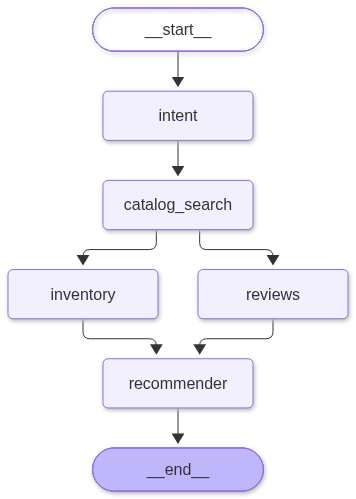

In [24]:
from IPython.display import Image, display, Markdown
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

BASE_MERMAID = graph.get_graph().draw_mermaid()

def show_graph(active=None, done=()):
    """Draw the graph. Green = finished, yellow = running now."""
    m = BASE_MERMAID
    for n in done:
        m += f"\n\tstyle {n} fill:#a5d6a7,stroke:#2e7d32,stroke-width:2px"
    for n in ([active] if isinstance(active, str) else (active or [])):
        m += f"\n\tstyle {n} fill:#ffd54f,stroke:#f57f17,stroke-width:4px"
    try:
        display(Image(draw_mermaid_png(m)))
    except Exception as e:   # offline fallback
        print("(PNG render failed, showing ASCII)", e)
        print(graph.get_graph().draw_ascii())

show_graph()

In [25]:
# ASCII version (works offline, good for a terminal)
print(graph.get_graph().draw_ascii())

           +-----------+            
           | __start__ |            
           +-----------+            
                  *                 
                  *                 
                  *                 
            +--------+              
            | intent |              
            +--------+              
                  *                 
                  *                 
                  *                 
        +----------------+          
        | catalog_search |          
        +----------------+          
           ***        ***           
          *              *          
        **                **        
+-----------+          +---------+  
| inventory |          | reviews |  
+-----------+          +---------+  
           ***        ***           
              *      *              
               **  **               
          +-------------+           
          | recommender |           
          +-------------+           
 

In [26]:
# Raw Mermaid code: paste into https://mermaid.live to edit it
print(BASE_MERMAID)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	intent(intent)
	catalog_search(catalog_search)
	inventory(inventory)
	reviews(reviews)
	recommender(recommender)
	__end__([<p>__end__</p>]):::last
	__start__ --> intent;
	catalog_search --> inventory;
	catalog_search --> reviews;
	intent --> catalog_search;
	inventory --> recommender;
	reviews --> recommender;
	recommender --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



## 7️⃣ Run it Live: Watch the Agents Step by Step 🎬
LangGraph runs in **super-steps**. Agents that run in parallel share the **same step number**,
so you'll see Inventory and Reviews light up **together**. 🟡 = running in this step, 🟢 = already finished.

In [27]:
def run_live(query: str):
    display(Markdown(f"### 🧑 Customer: *{query}*"))
    steps, final_state = {}, {}

    # "debug" events carry the super-step number, so parallel nodes can be grouped
    for mode, event in graph.stream({"query": query}, stream_mode=["debug", "values"]):
        if mode == "values":
            final_state = event
        elif event["type"] == "task_result":
            steps.setdefault(event["step"], []).append(event["payload"]["name"])

    # Replay each super-step with the graph highlighted
    done = []
    for i, (step, nodes) in enumerate(sorted(steps.items()), start=1):
        tag = "🔀 PARALLEL" if len(nodes) > 1 else "➡️ SEQUENTIAL"
        display(Markdown(f"---\n#### Step {i} {tag}: `{', '.join(nodes)}`"))
        show_graph(active=nodes, done=done)
        done += nodes
    display(Markdown("---\n### ✅ Final Recommendation\n" + final_state["final_answer"]))



### 🧑 Customer: *I need running shoes under $120, I like Nike*

🧭 Intent Agent: understanding the request...
   → category=shoes, budget=120.0, keywords=['running', 'Nike']
🔎 Catalog Search Agent: searching products...
   → found 2 candidates: ['Nike Air Zoom Pegasus', 'Puma Velocity Nitro']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

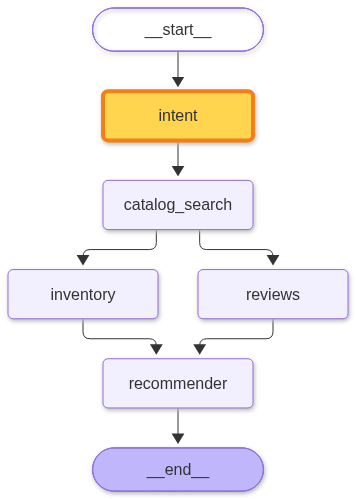

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

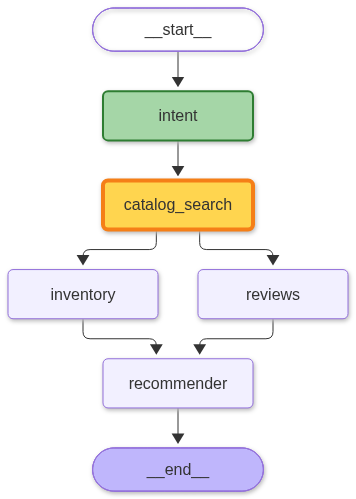

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

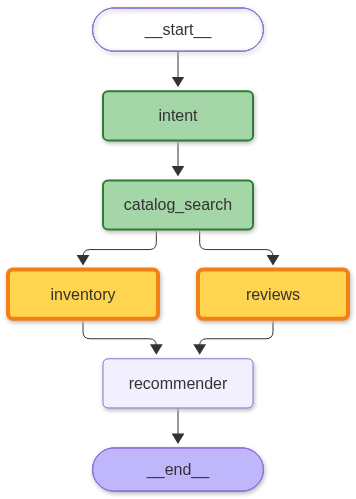

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

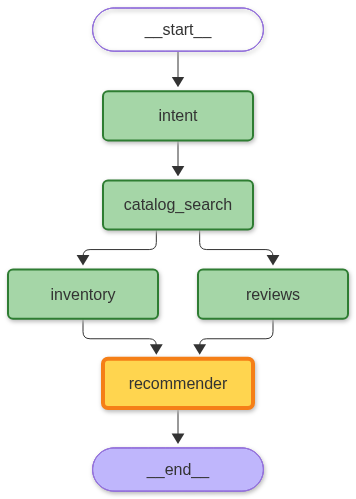

---
### ✅ Final Recommendation
Sure! Here’s the best option for you:

**Recommended Product:**
- **Nike Air Zoom Pegasus**
  - Price: $120
  - Average Rating: 4.5 (4 reviews)
  - Stock: In stock (12 units)
  - Delivery: 2 days

**Alternative Option:**
- **Puma Velocity Nitro**
  - Price: $95
  - Average Rating: 3.7 (3 reviews)
  - Stock: In stock (5 units)
  - Delivery: 3 days

The Nike Air Zoom Pegasus is a great choice if you want a highly-rated running shoe within your budget!

In [28]:
run_live("I need running shoes under $120, I like Nike")

## 8️⃣ Try More Queries

### 🧑 Customer: *Suggest good noise-cancelling headphones under 100 dollars*

🧭 Intent Agent: understanding the request...
   → category=headphones, budget=100.0, keywords=['noise-cancelling']
🔎 Catalog Search Agent: searching products...
   → found 2 candidates: ['JBL Tune 760NC', 'Boat Rockerz 450']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

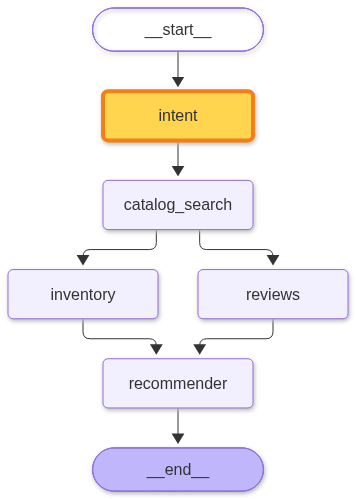

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

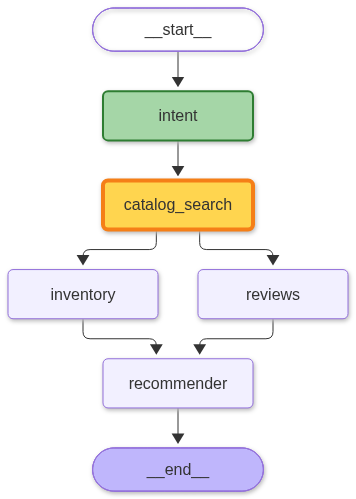

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

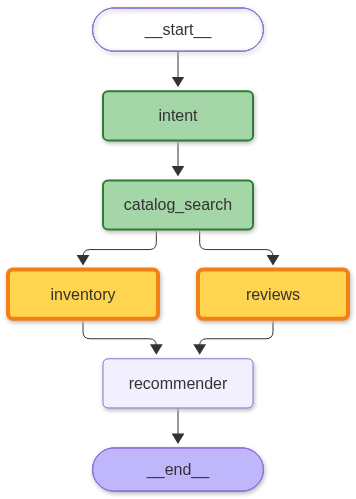

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

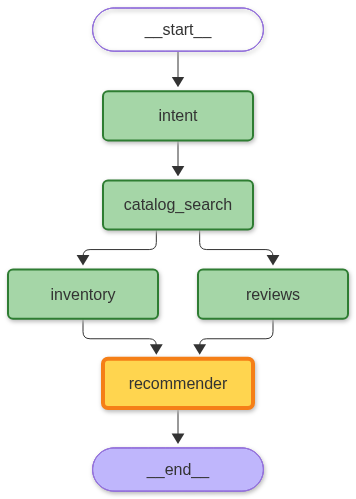

---
### ✅ Final Recommendation
Sure! Here’s a great option for noise-cancelling headphones under $100:

### Best Product:
- **JBL Tune 760NC**
  - **Price:** $90
  - **Average Rating:** 3.7 (3 reviews)
  - **Stock:** In stock (20 units available)
  - **Delivery:** 2 days

### Alternative:
- **Boat Rockerz 450**
  - **Price:** $25
  - **Average Rating:** 3.0 (4 reviews)
  - **Stock:** In stock (100 units available)
  - **Delivery:** 4 days

The JBL Tune 760NC offers better sound quality and features, making it the top choice!

In [29]:
run_live("Suggest good noise-cancelling headphones under 100 dollars")

### 🧑 Customer: *Show me running shoes under $100*

🧭 Intent Agent: understanding the request...
   → category=shoes, budget=100.0, keywords=['running']
🔎 Catalog Search Agent: searching products...
   → found 1 candidates: ['Puma Velocity Nitro']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

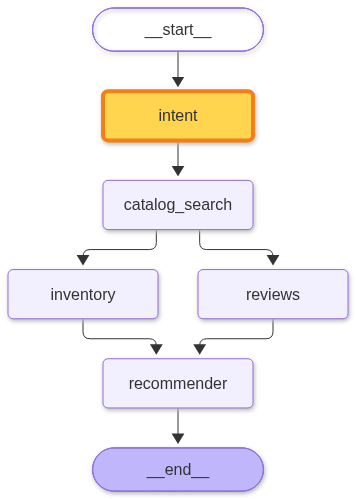

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

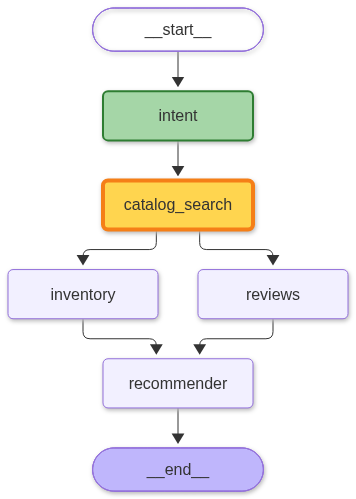

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

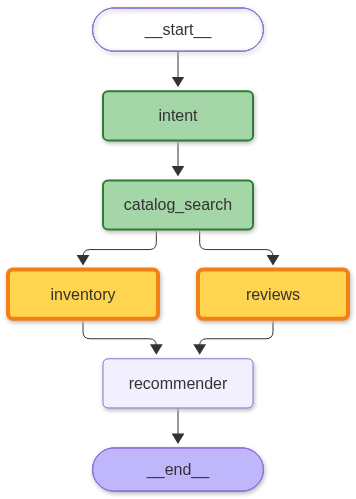

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

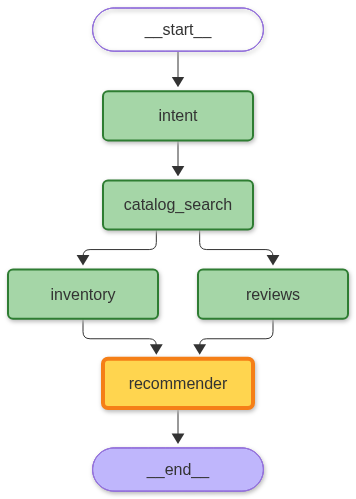

---
### ✅ Final Recommendation
Sure! Here’s a great option for running shoes under $100:

### Recommended Product:
- **Puma Velocity Nitro**
  - **Price:** $95
  - **Stock:** In stock (5 units available)
  - **Delivery:** 3 days
  - **Average Rating:** 3.7 (3 reviews)

### Alternative:
- **Nike Revolution 5**
  - **Price:** $85
  - **Stock:** In stock (10 units available)
  - **Delivery:** 2 days
  - **Average Rating:** 4.5 (15 reviews)

Both options are excellent for your running needs! Let me know if you’d like more information or assistance.

In [30]:
# 1. Budget filter: the Puma (and Nike, at exactly $120) qualify; Adidas ($180) is filtered out
run_live("Show me running shoes under $100")

### 🧑 Customer: *I want Adidas Ultraboost shoes*

🧭 Intent Agent: understanding the request...
   → category=shoes, budget=None, keywords=['Adidas', 'Ultraboost']
🔎 Catalog Search Agent: searching products...
   → found 3 candidates: ['Nike Air Zoom Pegasus', 'Adidas Ultraboost 22', 'Puma Velocity Nitro']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

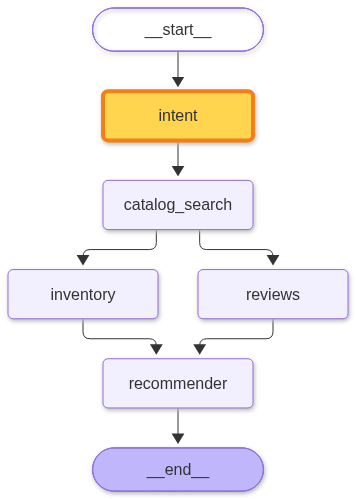

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

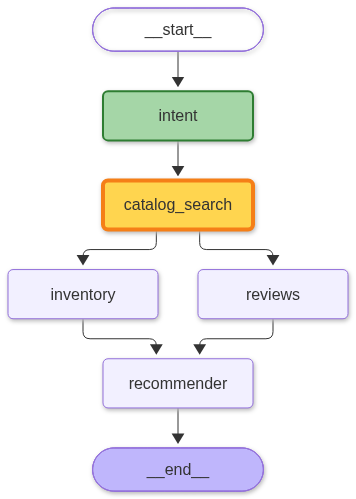

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

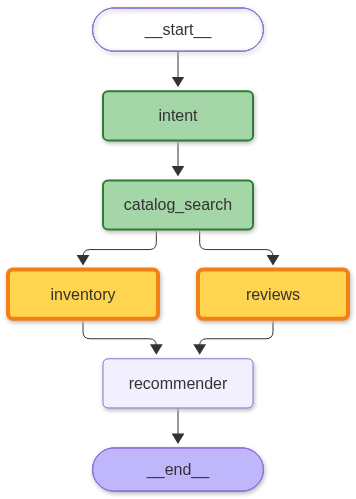

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

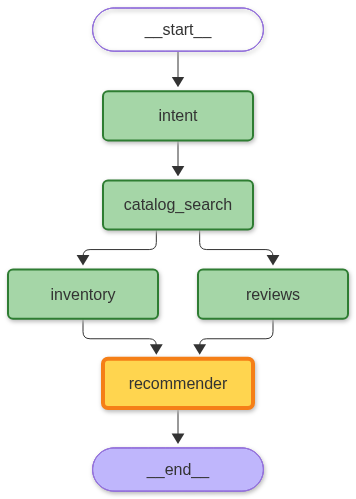

---
### ✅ Final Recommendation
Sure! Here’s what I recommend:

**Best Product:**
- **Nike Air Zoom Pegasus**
  - **Price:** $120
  - **Stock:** In stock (12 units available)
  - **Delivery:** 2 days
  - **Rating:** 4.5 (4 reviews)

**Alternative:**
- **Puma Velocity Nitro**
  - **Price:** $95
  - **Stock:** In stock (5 units available)
  - **Delivery:** 3 days
  - **Rating:** 3.7 (3 reviews)

Unfortunately, the Adidas Ultraboost 22 is currently out of stock. Let me know if you’d like to proceed with the Nike Air Zoom Pegasus or need more options!

In [31]:
# 2. Out of stock: the Adidas Ultraboost has 0 units, so the Recommender should skip it
run_live("I want Adidas Ultraboost shoes")

### 🧑 Customer: *What are the best headphones you have?*

🧭 Intent Agent: understanding the request...
   → category=headphones, budget=None, keywords=['best', 'quality']
🔎 Catalog Search Agent: searching products...
   → found 3 candidates: ['Sony WH-1000XM5', 'JBL Tune 760NC', 'Boat Rockerz 450']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

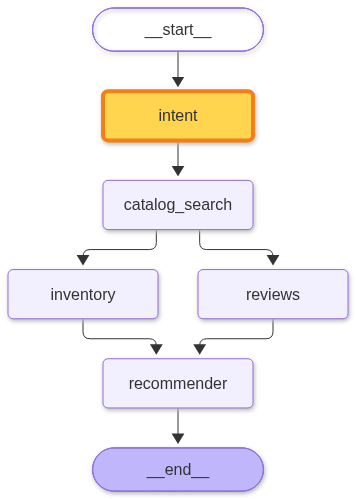

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

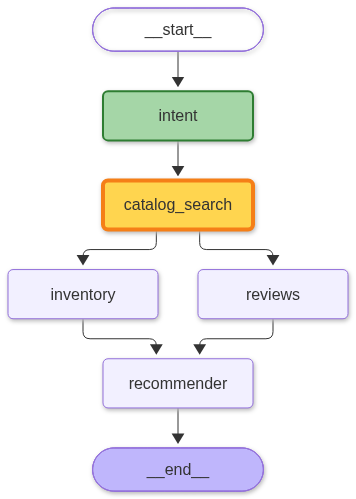

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

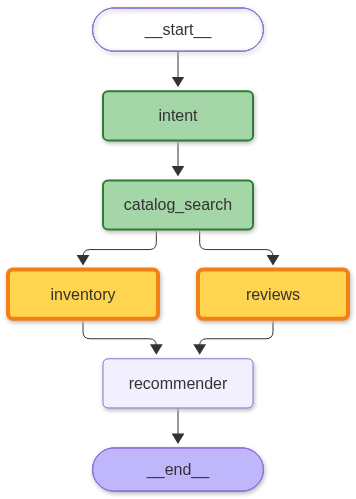

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

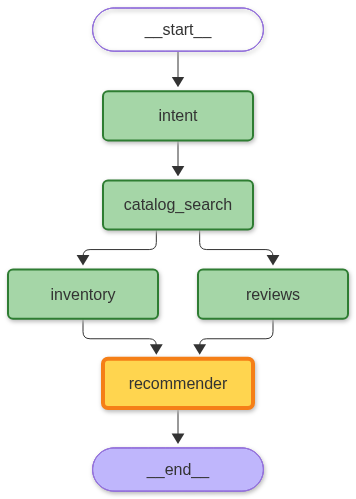

---
### ✅ Final Recommendation
The best headphones we have are:

- **Sony WH-1000XM5**
  - Price: $350
  - Average Rating: 4.8 (4 reviews)
  - Stock: In stock (3 units available)
  - Delivery: 1 day

As an alternative, you might consider:

- **JBL Tune 760NC**
  - Price: $90
  - Average Rating: 3.7 (3 reviews)
  - Stock: In stock (20 units available)
  - Delivery: 2 days

The Sony WH-1000XM5 offers superior sound quality and noise cancellation, making it a top choice!

In [32]:
# 3. No budget given: the Intent agent should return budget=None
run_live("What are the best headphones you have?")

### 🧑 Customer: *I want premium noise-cancelling headphones, money is no issue*

🧭 Intent Agent: understanding the request...
   → category=headphones, budget=None, keywords=['premium', 'noise-cancelling']
🔎 Catalog Search Agent: searching products...
   → found 3 candidates: ['Sony WH-1000XM5', 'JBL Tune 760NC', 'Boat Rockerz 450']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

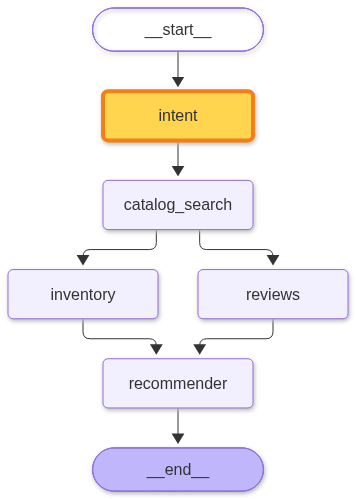

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

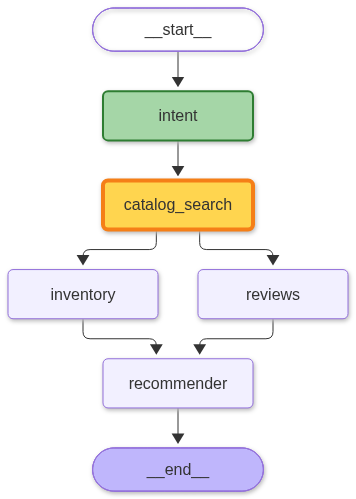

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

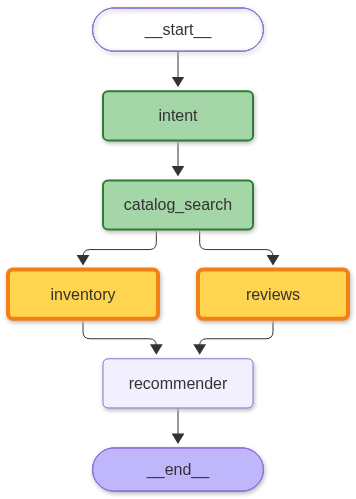

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

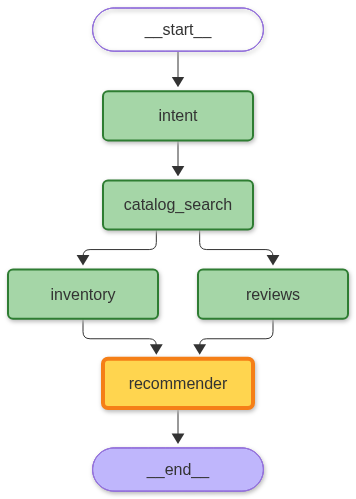

---
### ✅ Final Recommendation
I recommend the **Sony WH-1000XM5** for premium noise-cancelling headphones. Here are the details:

- **Sony WH-1000XM5**
  - Price: $350
  - Average Rating: 4.8 (4 reviews)
  - Stock: In stock (3 units available)
  - Delivery: 1 day

As an alternative, you might consider the **JBL Tune 760NC**:

- **JBL Tune 760NC**
  - Price: $90
  - Average Rating: 3.7 (3 reviews)
  - Stock: In stock (20 units available)
  - Delivery: 2 days

The Sony WH-1000XM5 offers superior sound quality and noise cancellation, making it the best choice!

In [33]:
# 4. Premium pick: the Sony is in stock and has the top rating (4.8)
run_live("I want premium noise-cancelling headphones, money is no issue")

### 🧑 Customer: *Cheapest headphones possible, I'm a student with $30*

🧭 Intent Agent: understanding the request...
   → category=headphones, budget=30.0, keywords=['cheapest', 'student']
🔎 Catalog Search Agent: searching products...
   → found 1 candidates: ['Boat Rockerz 450']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

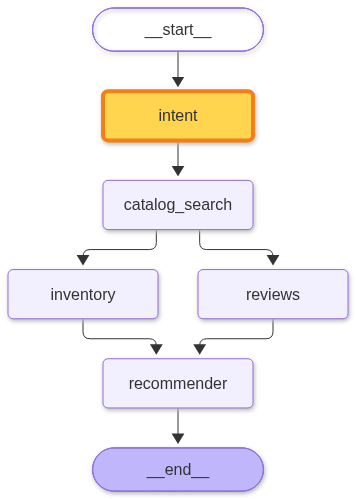

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

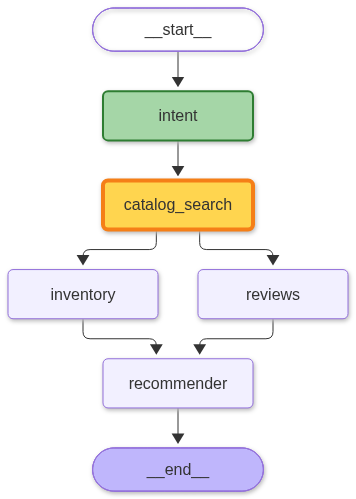

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

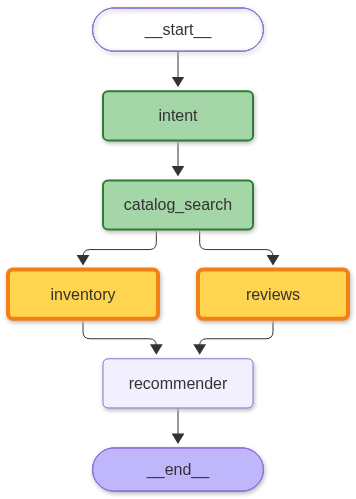

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

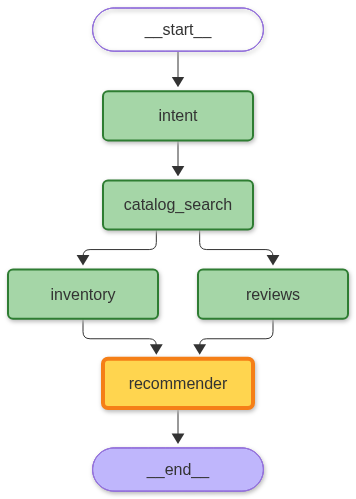

---
### ✅ Final Recommendation
Sure! Here’s a great option for you:

**Recommended Product:**
- **Boat Rockerz 450**
  - **Price:** $25
  - **Rating:** 3.0 (4 reviews)
  - **Stock:** In stock (100 units available)
  - **Delivery:** 4 days

**Alternative:**
- **Generic Wired Headphones**
  - **Price:** $15
  - **Rating:** 4.0 (10 reviews)
  - **Stock:** In stock
  - **Delivery:** 3 days

The Boat Rockerz 450 is a solid choice if you prefer wireless, while the generic option is budget-friendly and has good reviews. Happy shopping!

In [34]:
# 5. Very low budget: only the Boat Rockerz ($25) fits
run_live("Cheapest headphones possible, I'm a student with $30")

### 🧑 Customer: *I want an Apple Watch under $300*

🧭 Intent Agent: understanding the request...
   → category=watch, budget=300.0, keywords=['Apple']
🔎 Catalog Search Agent: searching products...
   → found 3 candidates: ['Apple Watch SE', 'Noise ColorFit Pro 5', 'Samsung Galaxy Watch 6']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

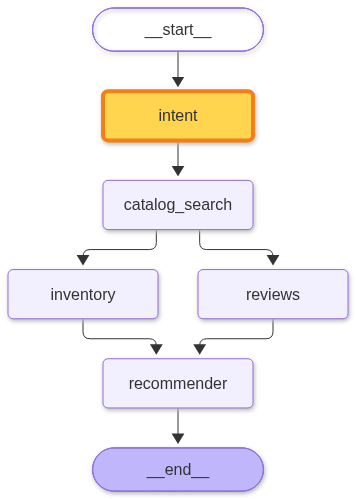

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

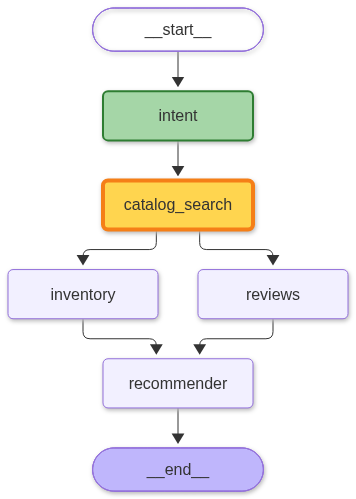

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

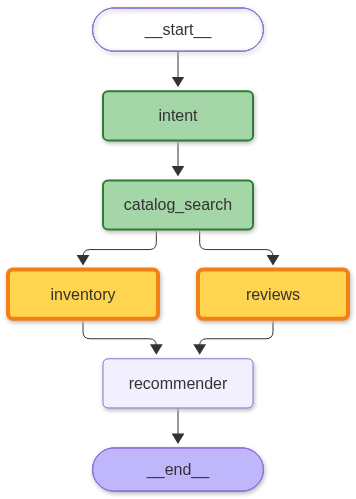

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

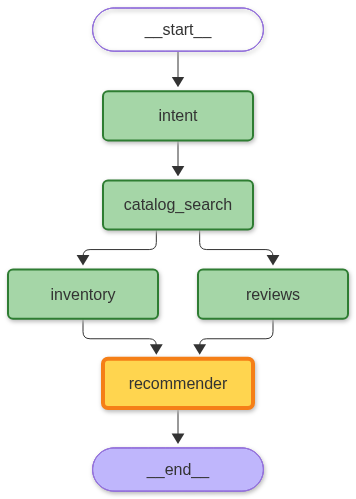

---
### ✅ Final Recommendation
Here’s the best option for you:

- **Samsung Galaxy Watch 6**
  - Price: $280
  - Stock: In stock (7 units available)
  - Average Rating: 4.3 (3 reviews)
  - Delivery: 3 days

**Alternative:**

- **Noise ColorFit Pro 5**
  - Price: $60
  - Stock: In stock (40 units available)
  - Average Rating: 3.8 (4 reviews)
  - Delivery: 2 days

The Samsung Galaxy Watch 6 is a great choice within your budget, while the Noise ColorFit Pro 5 offers a more affordable option. Let me know if you need more information!

In [35]:
# 6. Out-of-stock brand request: the Apple Watch SE has 0 units, so expect an alternative
run_live("I want an Apple Watch under $300")

### 🧑 Customer: *Need a fitness smartwatch below 100 dollars*

🧭 Intent Agent: understanding the request...
   → category=watch, budget=100.0, keywords=['fitness', 'smartwatch']
🔎 Catalog Search Agent: searching products...
   → found 1 candidates: ['Noise ColorFit Pro 5']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

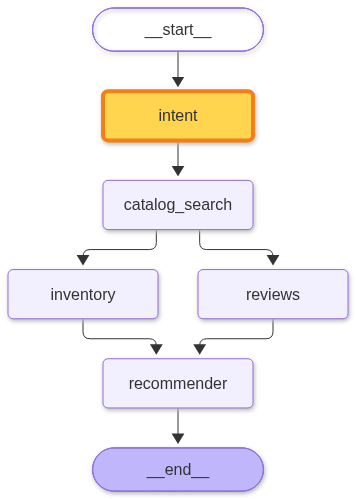

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

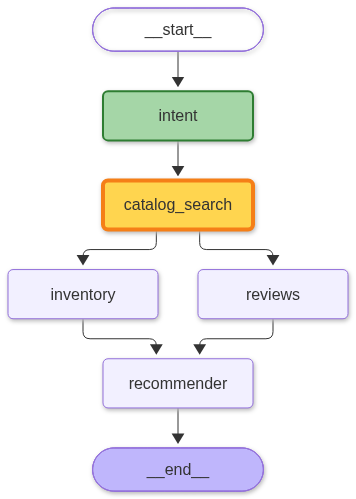

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

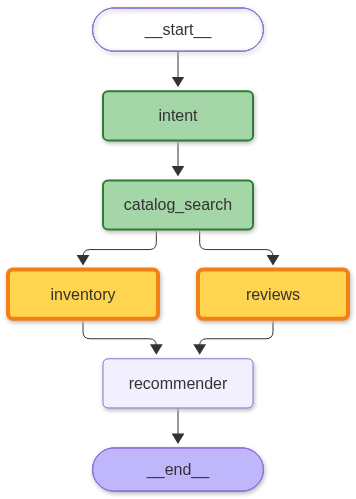

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

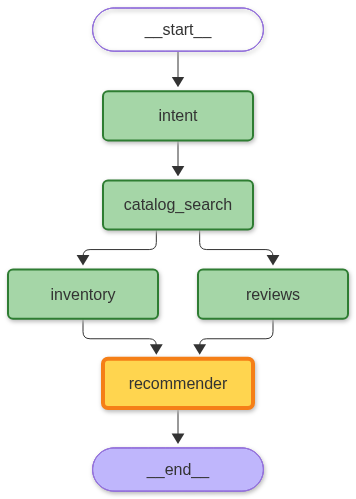

---
### ✅ Final Recommendation
Sure! Here’s a great option for you:

### Recommended Product:
- **Noise ColorFit Pro 5**
  - **Price:** $60
  - **Rating:** 3.8 (4 reviews)
  - **Stock:** In stock (40 units available)
  - **Delivery:** 2 days

### Alternative:
- **Amazfit Bip U Lite**
  - **Price:** Approximately $70 (check availability)
  - **Rating:** Generally well-reviewed
  - **Features:** Heart rate monitoring, sleep tracking, and more

Both options are excellent for fitness tracking while staying within your budget! Let me know if you need more information.

In [36]:
# 7. Smartwatch with a mid-range budget: Noise ($60) fits
run_live("Need a fitness smartwatch below 100 dollars")

### 🧑 Customer: *Which watch has the best customer reviews?*

🧭 Intent Agent: understanding the request...
   → category=watch, budget=None, keywords=['best customer reviews']
🔎 Catalog Search Agent: searching products...
   → found 3 candidates: ['Apple Watch SE', 'Noise ColorFit Pro 5', 'Samsung Galaxy Watch 6']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

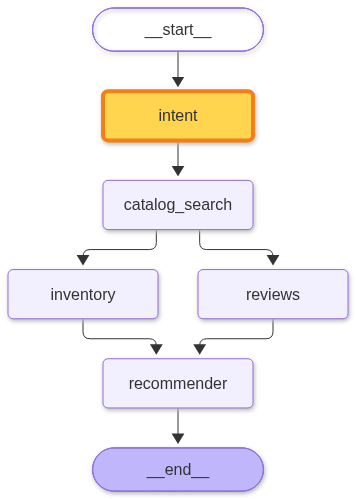

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

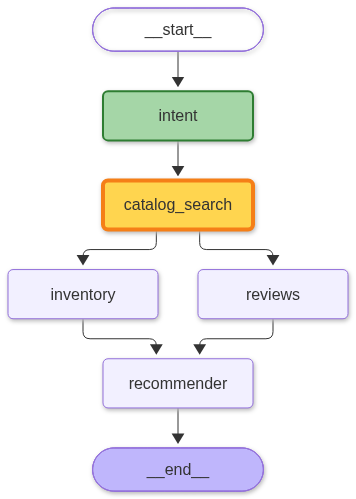

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

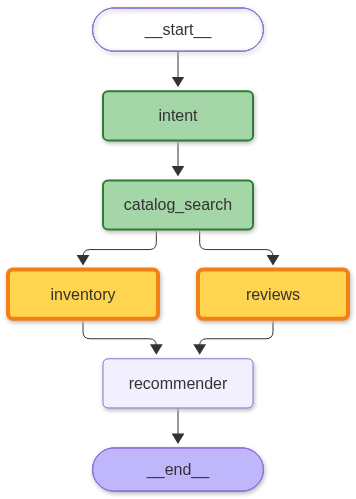

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

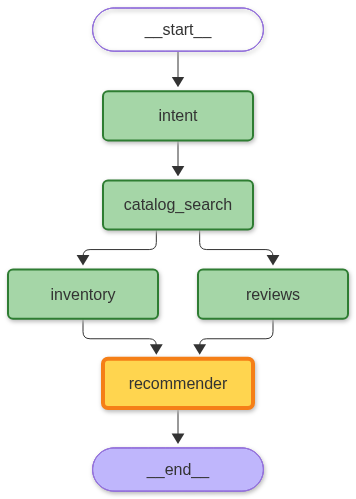

---
### ✅ Final Recommendation
Based on customer reviews and availability, I recommend the following watch:

- **Best Choice: Noise ColorFit Pro 5**
  - **Rating:** 3.8 (4 reviews)
  - **Price:** $60
  - **Stock:** In stock (40 units available)
  - **Delivery:** 2 days

**Alternative: Samsung Galaxy Watch 6**
- **Rating:** 4.3 (3 reviews)
- **Price:** $280
- **Stock:** In stock (7 units available)
- **Delivery:** 3 days

While the Samsung Galaxy Watch 6 has a higher rating, the Noise ColorFit Pro 5 is the best option considering your budget and availability.

In [37]:
# 8. Rating-focused: the Recommender should weigh the review scores
run_live("Which watch has the best customer reviews?")

### 🧑 Customer: *I need headphones delivered by tomorrow, budget $400*

🧭 Intent Agent: understanding the request...
   → category=headphones, budget=400.0, keywords=['delivery', 'tomorrow']
🔎 Catalog Search Agent: searching products...
   → found 3 candidates: ['Sony WH-1000XM5', 'JBL Tune 760NC', 'Boat Rockerz 450']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

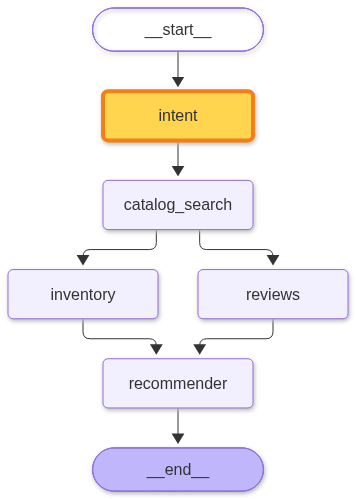

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

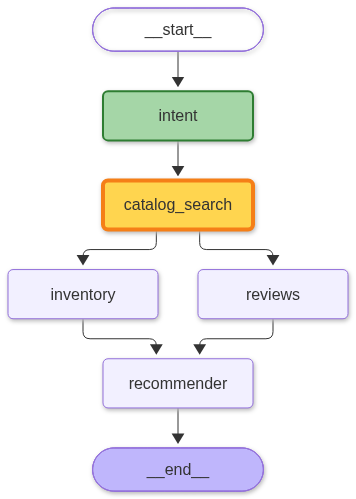

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

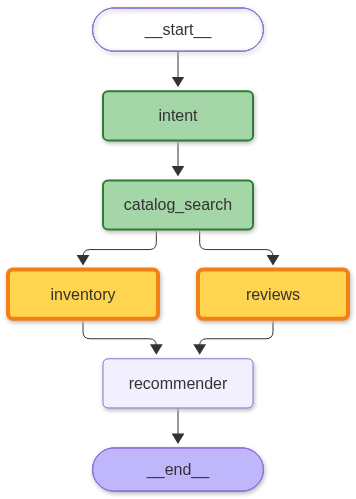

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

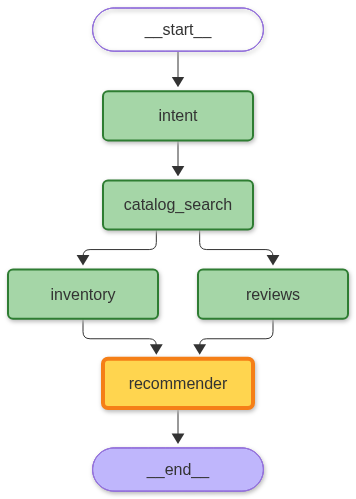

---
### ✅ Final Recommendation
Sure! Here’s the best option for you:

**Best Product:**
- **Sony WH-1000XM5**
  - Price: $350
  - Delivery: Tomorrow (1 day)
  - Average Rating: 4.8 (from 4 reviews)
  - In Stock: Yes (3 units available)

**Alternative:**
- **JBL Tune 760NC**
  - Price: $90
  - Delivery: 2 days
  - Average Rating: 3.7 (from 3 reviews)
  - In Stock: Yes (20 units available)

The Sony WH-1000XM5 offers excellent sound quality and comfort, making it a great choice within your budget!

In [38]:
# 9. Fast delivery: Sony delivers in 1 day, so delivery days should matter here
run_live("I need headphones delivered by tomorrow, budget $400")

### 🧑 Customer: *Gift for my brother who loves jogging, around $130*

🧭 Intent Agent: understanding the request...
   → category=shoes, budget=130.0, keywords=['gift', 'brother', 'jogging']
🔎 Catalog Search Agent: searching products...
   → found 2 candidates: ['Nike Air Zoom Pegasus', 'Puma Velocity Nitro']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...


---
#### Step 1 ➡️ SEQUENTIAL: `intent`

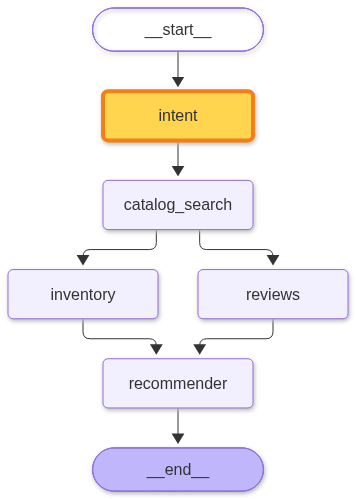

---
#### Step 2 ➡️ SEQUENTIAL: `catalog_search`

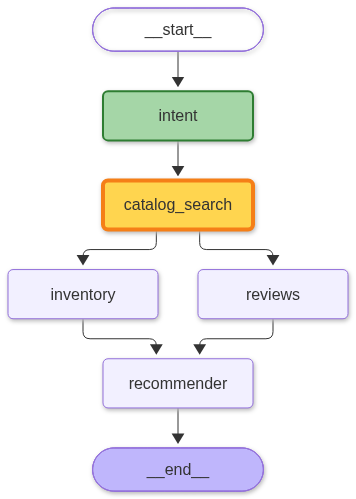

---
#### Step 3 🔀 PARALLEL: `inventory, reviews`

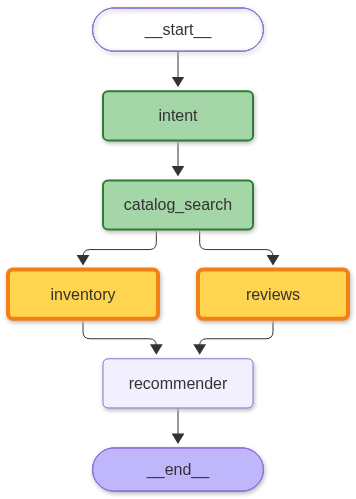

---
#### Step 4 ➡️ SEQUENTIAL: `recommender`

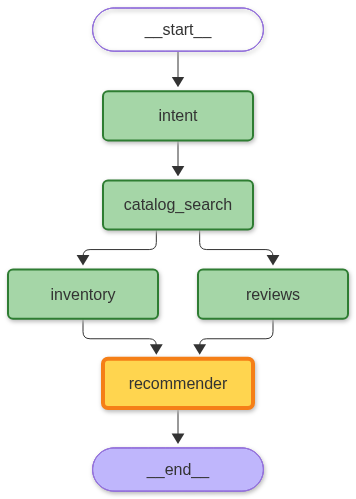

---
### ✅ Final Recommendation
I recommend the following gift for your brother who loves jogging:

- **Nike Air Zoom Pegasus**
  - Price: $120
  - Average Rating: 4.5 (from 4 reviews)
  - In Stock: Yes (12 units available)
  - Delivery: 2 days

**Alternative:**
- **Puma Velocity Nitro**
  - Price: $95
  - Average Rating: 3.7 (from 3 reviews)
  - In Stock: Yes (5 units available)
  - Delivery: 3 days

The Nike Air Zoom Pegasus is a great choice for its high rating and comfort, perfect for jogging!

In [39]:
# 10. Gift scenario: the Intent agent has to infer the category from context
run_live("Gift for my brother who loves jogging, around $130")

In [40]:
# Quick run without the pictures: just the final state
result = graph.invoke({"query": "Cheap smartwatch for fitness, budget $70"})
print(result["final_answer"])

🧭 Intent Agent: understanding the request...
   → category=watch, budget=70.0, keywords=['cheap', 'smartwatch', 'fitness']
🔎 Catalog Search Agent: searching products...
   → found 1 candidates: ['Noise ColorFit Pro 5']
📦 Inventory Agent: checking stock...
⭐ Review Agent: analysing ratings...
🤝 Recommender Agent: combining all reports...
Sure! Here’s a great option for you:

### Recommended Product:
- **Noise ColorFit Pro 5**
  - **Price:** $60
  - **Rating:** 3.8 (4 reviews)
  - **Stock:** In stock (40 units available)
  - **Delivery:** 2 days

### Alternative:
- **Amazfit Bip U Lite**
  - **Price:** Approximately $70 (check for availability)
  - **Rating:** Generally well-reviewed for fitness tracking features

The Noise ColorFit Pro 5 is a solid choice within your budget, offering good functionality for fitness tracking. Let me know if you need more information!


## 🎓 Key Takeaways for Students
1. **State** is a shared dictionary that every agent reads and updates.
2. **Nodes** are agents. Some use an LLM, some are plain Python.
3. **Sequential edge:** `add_edge("A", "B")` means B runs after A.
4. **Parallel edges:** several edges *from the same node* run in the **same super-step**.
5. **Fan-in:** `add_edge(["A","B","C"], "D")` means D waits for **all** of them.
6. Parallel nodes should write to **different state keys**. If they share one key, give it a reducer such as `Annotated[list, operator.add]`.

### 🧪 Exercises
- Add a **Pricing Agent** (use `DISCOUNTS` and `COUPON`) as a third parallel branch.
- Add a **conditional edge**: if `candidates` is empty, go straight to END.
- Add more products to the mock data.